<a href="https://colab.research.google.com/github/sinbbang/BigData/blob/main/10%EC%9E%A5_%EC%8B%A4%EC%8A%B503_%EA%B3%B5%ED%9C%B4%EC%9D%BC%EB%8D%B0%EC%9D%B4%ED%84%B0%EB%A1%9C_%EC%97%B0%EC%B0%A8%EA%B3%84%ED%9A%8D%ED%91%9C%EB%A7%8C%EB%93%A4%EA%B8%B0_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습 ③ 공휴일 데이터로 연차 계획표 만들기 📅

**10장 공공데이터와 API 연동 | Google Colab**

> **오늘 만드는 것:** 연도를 입력하면 공휴일 목록을 정리하고, 연차 **1~2일**로 만들 수 있는 연휴 후보를 찾아 **엑셀 파일**로 저장합니다.
>
> **중요:** 기본값은 **연습 모드**입니다. 화면에 표시되는 연습 데이터는 *공휴일 전체가 아닌 일부 예시*이므로 실제 연차 신청에 사용하지 마세요. **실제 모드**는 발급받은 API 인증키가 필요합니다.

**학습 목표**
1. 클라이언트가 API에 요청하고 서버가 응답하는 과정을 설명할 수 있다.
2. API 요청에 `solYear`, `solMonth`, `serviceKey`가 쓰이는 이유를 알 수 있다.
3. JSON 응답의 `items → item`에서 필요한 값(`locdate`, `dateName`, `isHoliday`)을 찾을 수 있다.
4. 토·일요일과 공휴일을 고려해 연차 계획표를 만든다.
5. 결과를 CSV와 엑셀 파일로 내려받는다.

**실습 순서:** 데이터 준비 → 인증키/설정 → 응답 확인 → 값 추출 → 연차 후보 계산 → 표·엑셀 → 검증

**데이터 출처(실제 모드):** [공공데이터포털 한국천문연구원 특일 정보](https://www.data.go.kr/data/15012690/openapi.do) (`getRestDeInfo`). API 응답은 XML이 기본이고 `_type=json`으로 JSON을 요청할 수 있습니다. 제공 정책/공휴일은 변경될 수 있습니다.

## STEP 1. Colab 준비: 실행 모드와 연도 정하기 (5분)

코드를 처음 읽을 때는 `=` 오른쪽 값을 왼쪽 이름에 저장한다고 생각하세요. **아래 셀의 두 줄만 바꾸면** 됩니다.

- `실행모드 = "연습"` : 인증키가 없어도 실행됩니다.
- `실행모드 = "실제"` : 국가 공공데이터 API를 호출합니다.
- `조회연도` : 실제 모드에서는 조회하고 싶은 연도입니다. 연습 모드는 **2026년 예시만** 지원합니다.

In [1]:
# "연습" 또는 "실제" 가운데 하나를 선택합니다.
실행모드 = "연습"

# 조회하려는 연도를 숫자로 입력합니다. 예: 2026, 2027
조회연도 = 2026

# 연차를 최대 며칠까지 쓸 수 있는지 설정합니다. (1일 또는 2일 권장)
최대연차일수 = 2

# 잘못된 입력은 다음 단계로 넘어가기 전에 알려 줍니다.
assert 실행모드 in ("연습", "실제"), '실행모드는 "연습" 또는 "실제"여야 합니다.'
assert 2000 <= 조회연도 <= 2100, "조회연도를 다시 확인해 주세요."
assert 1 <= 최대연차일수 <= 5, "최대연차일수는 1~5 사이로 설정해 주세요."
assert 실행모드 != "연습" or 조회연도 == 2026, "연습 모드는 2026년만 지원합니다."

print(f"현재 설정: {실행모드} 모드 / {조회연도}년 / 연차 최대 {최대연차일수}일")

현재 설정: 연습 모드 / 2026년 / 연차 최대 2일


## STEP 2. 필요한 도구 가져오기

`import`는 이미 만들어진 기능을 가져오는 명령입니다. Colab에는 보통 아래 도구가 설치되어 있습니다.

In [2]:
# datetime: 날짜를 하루씩 더하고 요일을 확인하는 데 사용합니다.
from datetime import date, timedelta

# json: API의 JSON 응답 구조를 화면에 보기 좋게 출력합니다.
import json

# requests: 실제 모드에서 공공데이터 API 주소에 접속합니다.
import requests

# pandas: 공휴일과 연차 후보를 보기 좋은 표로 만듭니다.
import pandas as pd

# display: Colab 화면에 표를 표시합니다.
from IPython.display import display

# pathlib: CSV와 엑셀 파일의 저장 위치를 관리합니다.
from pathlib import Path

print("준비 완료! ✅")

준비 완료! ✅


## STEP 3. API 응답 받아오기

**실제 API의 주문서**

`https://apis.data.go.kr/B090041/openapi/service/SpcdeInfoService/getRestDeInfo`

요청 매개변수: `serviceKey`(내 인증키), `solYear`(연도), `solMonth`(월), `_type=json`(JSON 형식), `numOfRows`(한 페이지 건수).

실제 모드를 이용하려면 공공데이터포털의 **한국천문연구원 특일 정보**에서 활용신청을 완료하고, Colab 좌측의 **열쇠(Secrets)** 메뉴에서 `DATA_GO_KR_KEY`라는 이름으로 인증키를 등록하세요. **노트북 셀에 인증키를 직접 적거나 공유하지 마세요.**

**연습 데이터 안내:** 2026년의 *일부 날짜만* 넣은 교육용 JSON 구조입니다. 실제 데이터 전체, 연휴 추천의 정확도를 보장하지 않으며, 별도 실시간 데이터를 받은 것이 아닙니다.

In [3]:
# 실제 API가 제공하는 JSON 형태를 흉내 낸 "연습용 일부 데이터"입니다.
# ※ 공휴일 전체가 아니라 몇 개 날짜만 골라 놓은 예제입니다.
연습응답 = {
    "response": {
        "header": {"resultCode": "00", "resultMsg": "NORMAL SERVICE."},
        "body": {
            "items": {
                "item": [
                    {"locdate": 20260101, "dateName": "신정", "isHoliday": "Y"},
                    {"locdate": 20260301, "dateName": "삼일절", "isHoliday": "Y"},
                    {"locdate": 20260505, "dateName": "어린이날", "isHoliday": "Y"},
                    {"locdate": 20260815, "dateName": "광복절", "isHoliday": "Y"},
                    {"locdate": 20261009, "dateName": "한글날", "isHoliday": "Y"},
                    {"locdate": 20261225, "dateName": "기독탄신일", "isHoliday": "Y"}
                ]
            },
            "totalCount": 6
        }
    }
}

# 실제 모드에서는 아래 함수가 1월부터 12월까지 API를 조회합니다.
def 실제공휴일가져오기(연도):
    # Colab의 비밀정보(Secrets)에 저장한 키를 가져옵니다.
    from google.colab import userdata
    인증키 = userdata.get("DATA_GO_KR_KEY")

    # 인증키를 찾을 수 없으면 해결 방법을 알려 줍니다.
    if not 인증키:
        raise ValueError("Colab Secrets에 DATA_GO_KR_KEY를 등록해 주세요.")

    # 한국천문연구원의 공휴일 조회 API 주소입니다.
    주소 = "https://apis.data.go.kr/B090041/openapi/service/SpcdeInfoService/getRestDeInfo"
    전체목록 = []

    # 공휴일은 1월부터 12월까지 월별로 요청합니다.
    for 월 in range(1, 13):
        # 주소에 붙일 매개변수를 딕셔너리로 만듭니다.
        요청값 = {
            "serviceKey": 인증키,
            "solYear": str(연도),
            "solMonth": f"{월:02d}",
            "_type": "json",
            "numOfRows": "100",
            "pageNo": "1"
        }

        # timeout을 넣어 응답이 없을 때 무한정 기다리지 않게 합니다.
        응답 = requests.get(주소, params=요청값, timeout=20)
        응답.raise_for_status()  # HTTP 오류(예: 403, 500)가 있으면 알려 줍니다.

        # 인증 오류가 XML 문서로 내려오는 경우도 있어 먼저 검사합니다.
        try:
            자료 = 응답.json()
        except ValueError as 오류:
            raise ValueError(f"{월}월 응답이 JSON이 아닙니다. 인증키/서비스 승인/응답형식을 확인하세요.") from 오류

        # API가 보낸 성공 여부를 확인합니다.
        헤더 = 자료.get("response", {}).get("header", {})
        if str(헤더.get("resultCode", "")) != "00":
            raise ValueError(f"{월}월 API 오류: {헤더.get('resultMsg', '오류 메시지 없음')}")

        # 공휴일이 없는 달에는 items가 빈 문자열/빈 딕셔너리일 수 있습니다.
        본문 = 자료.get("response", {}).get("body", {})
        항목묶음 = 본문.get("items") or {}
        항목 = 항목묶음.get("item", []) if isinstance(항목묶음, dict) else []

        # 결과가 1건이면 딕셔너리, 여러 건이면 리스트가 될 수 있습니다.
        if isinstance(항목, dict):
            항목 = [항목]
        if not isinstance(항목, list):
            raise ValueError(f"{월}월 항목 구조가 예상과 다릅니다.")

        # 해당 월의 공휴일을 연간 목록에 이어 붙입니다.
        전체목록.extend(항목)
        print(f"{월:02d}월 확인: {len(항목)}건")

    # 이후 단계에서 동일하게 처리하도록 API 응답 구조로 맞춥니다.
    return {"response": {"header": {"resultCode": "00"},
                         "body": {"items": {"item": 전체목록},
                                  "totalCount": len(전체목록)}}}


# 선택한 실행모드에 따라 연습 응답 또는 실제 응답을 가져옵니다.
if 실행모드 == "연습":
    원본응답 = 연습응답
    print("🧪 연습용 일부 공휴일 데이터 6건을 사용합니다. 실제 연휴 계획에 사용하지 마세요.")
else:
    try:
        원본응답 = 실제공휴일가져오기(조회연도)
        print("✅ 공공데이터 API 조회를 마쳤습니다.")
    except Exception as 오류:
        # 실제 데이터 조회가 실패했다고 가짜 결과를 실제 결과인 것처럼 보여 주지 않습니다.
        raise RuntimeError(f"실제 API 조회 실패: {오류} (인증키와 활용신청 상태를 확인하세요.)") from 오류

🧪 연습용 일부 공휴일 데이터 6건을 사용합니다. 실제 연휴 계획에 사용하지 마세요.


## STEP 4. JSON 속에서 원하는 항목 찾기

JSON은 **상자 안에 또 상자가 있는 구조**입니다. `response → body → items → item`을 따라가세요. 필요한 세 가지 값은 다음과 같습니다.

- `locdate`: 날짜(예: `20260101`)
- `dateName`: 공휴일 이름(예: `신정`)
- `isHoliday`: 공공기관 휴일 여부(`Y` 또는 `N`)

In [4]:
# 응답의 앞부분만 출력하여 JSON에 어떤 항목이 들어 있는지 살펴봅니다.
print("JSON 응답 일부 보기:")
print(json.dumps(원본응답, ensure_ascii=False, indent=2)[:1200])

# 사전(dict)에서 단계적으로 데이터 목록을 꺼냅니다.
본문 = 원본응답["response"]["body"]
공휴일항목 = 본문["items"]["item"]

# 한 건만 내려오면 리스트 하나로 만들어 반복 처리를 쉽게 합니다.
if isinstance(공휴일항목, dict):
    공휴일항목 = [공휴일항목]

print(f"\n읽어 온 항목 수: {len(공휴일항목)}건")

JSON 응답 일부 보기:
{
  "response": {
    "header": {
      "resultCode": "00",
      "resultMsg": "NORMAL SERVICE."
    },
    "body": {
      "items": {
        "item": [
          {
            "locdate": 20260101,
            "dateName": "신정",
            "isHoliday": "Y"
          },
          {
            "locdate": 20260301,
            "dateName": "삼일절",
            "isHoliday": "Y"
          },
          {
            "locdate": 20260505,
            "dateName": "어린이날",
            "isHoliday": "Y"
          },
          {
            "locdate": 20260815,
            "dateName": "광복절",
            "isHoliday": "Y"
          },
          {
            "locdate": 20261009,
            "dateName": "한글날",
            "isHoliday": "Y"
          },
          {
            "locdate": 20261225,
            "dateName": "기독탄신일",
            "isHoliday": "Y"
          }
        ]
      },
      "totalCount": 6
    }
  }
}

읽어 온 항목 수: 6건


## STEP 5. 공휴일만 뽑아 표 만들기

날짜를 `YYYY-MM-DD`로 바꾸고, `isHoliday`가 `Y`인 항목만 사용합니다. 같은 날짜의 중복 항목도 정리합니다.

In [5]:
# 공휴일 한 건을 보기 좋은 형태로 바꾸어 담을 빈 리스트입니다.
정리된공휴일 = []

# API에서 가져온 각 항목을 하나씩 확인합니다.
for 항목 in 공휴일항목:
    # 공공기관 휴일로 표시되지 않은 항목은 제외합니다.
    if str(항목.get("isHoliday", "N")).upper() != "Y":
        continue

    # 20260101 같은 숫자를 실제 날짜 자료형으로 바꿉니다.
    날짜글자 = str(항목["locdate"])
    날짜 = pd.to_datetime(날짜글자, format="%Y%m%d", errors="raise").date()

    # 이후 표에서 쓰기 편한 항목만 새로 저장합니다.
    정리된공휴일.append({"날짜": 날짜, "공휴일명": str(항목["dateName"])})

# pandas.DataFrame은 데이터를 엑셀처럼 행과 열이 있는 표로 바꿉니다.
공휴일표 = pd.DataFrame(정리된공휴일, columns=["날짜", "공휴일명"])

# 중복 날짜의 명칭은 쉼표로 합쳐서 공휴일 날짜가 두 번 계산되지 않게 합니다.
if not 공휴일표.empty:
    공휴일표 = (공휴일표.groupby("날짜", as_index=False)["공휴일명"]
                 .agg(lambda 이름들: ", ".join(dict.fromkeys(이름들)))
                 .sort_values("날짜").reset_index(drop=True))

# 월과 요일 열을 추가해 보고서에서 쉽게 읽을 수 있게 합니다.
요일이름 = ["월", "화", "수", "목", "금", "토", "일"]
공휴일표["월"] = 공휴일표["날짜"].apply(lambda 날: 날.month)
공휴일표["요일"] = 공휴일표["날짜"].apply(lambda 날: 요일이름[날.weekday()])

# 행이 너무 길어지지 않도록 처음 20개만 미리 보여 줍니다.
print(f"총 {len(공휴일표)}개 공휴일 날짜를 확인했습니다.")
display(공휴일표.head(20))

총 6개 공휴일 날짜를 확인했습니다.


,날짜,공휴일명,월,요일
0,2026-01-01,신정,1,목
1,2026-03-01,삼일절,3,일
2,2026-05-05,어린이날,5,화
3,2026-08-15,광복절,8,토
4,2026-10-09,한글날,10,금
5,2026-12-25,기독탄신일,12,금


## STEP 6. 월별 공휴일 현황 보기

막대그래프로 어느 달에 **평일에 해당하는 공휴일**이 많은지 비교합니다. 토·일요일에 겹치는 공휴일은 별도로 구분합니다. (연습 모드는 일부 예제 데이터만 반영)

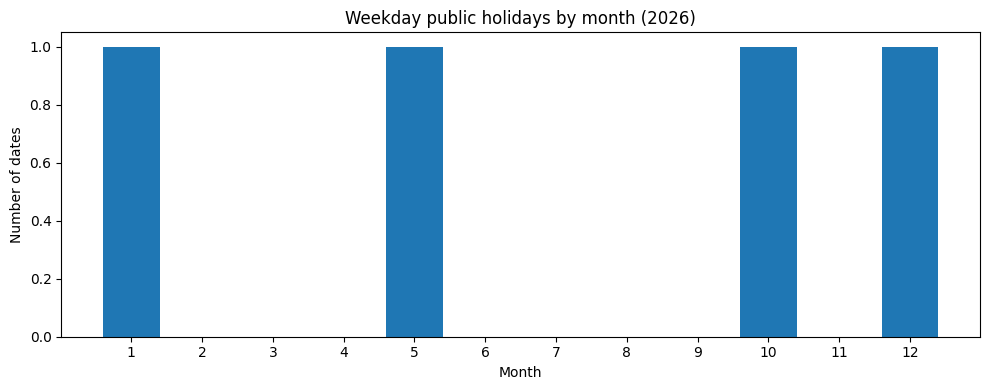

월별 평일 공휴일 수: {1: np.int64(1), 2: np.int64(0), 3: np.int64(0), 4: np.int64(0), 5: np.int64(1), 6: np.int64(0), 7: np.int64(0), 8: np.int64(0), 9: np.int64(0), 10: np.int64(1), 11: np.int64(0), 12: np.int64(1)}


In [6]:
# 평일은 weekday()가 0(월요일)부터 4(금요일)까지입니다.
평일공휴일표 = 공휴일표[공휴일표["날짜"].apply(lambda 날: 날.weekday() < 5)].copy()

# 1~12월에 평일 공휴일이 몇 번 있었는지 셉니다.
월별건수 = 평일공휴일표.groupby("월").size().reindex(range(1, 13), fill_value=0)

# 한글 폰트 추가 설치 없이 Colab에서도 잘 나오도록 축에는 숫자와 영어를 사용합니다.
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.bar([str(월) for 월 in 월별건수.index], 월별건수.values)
plt.title(f"Weekday public holidays by month ({조회연도})")
plt.xlabel("Month")
plt.ylabel("Number of dates")
plt.tight_layout()
plt.show()

# 정확한 건수도 텍스트로 출력합니다.
print("월별 평일 공휴일 수:", dict(월별건수))

## STEP 7. 연차 1~2일로 만들 수 있는 연휴 후보 계산하기

**계산 규칙**

- 토·일요일과 API가 확인한 공휴일은 **연차를 사용하지 않는 날**로 봅니다.
- 월~금요일이면서 공휴일이 아닌 날은 **연차 1일**이 필요합니다.
- 연차 사용량이 `1~최대연차일수`인 **연속된 날짜**를 후보로 찾습니다.
- 후보에는 확인된 공휴일이 최소 하루 포함되도록 합니다.
- 같은 기간 안에서 날짜를 더 늘릴 수 있는 후보를 간단히 정리합니다.

**주의:** 회사별 휴무일, 근로형태, 사내 규정, 선거일·임시공휴일의 추가 지정 등은 별도 확인이 필요합니다. 연습 모드는 공휴일이 누락된 *일부 데이터*이므로 연휴 후보도 교육용입니다.

In [7]:
# 공휴일이 포함된 날짜를 집합(set)에 담으면 "이 날짜가 공휴일인가?"를 빠르게 확인할 수 있습니다.
공휴일날짜집합 = set(공휴일표["날짜"])

# 어떤 하루가 근무일인지 판단합니다. (주 5일 근무하는 직장 기준)
def 근무일인가(날짜):
    # 월~금요일이면서 공휴일이 아니어야 실제 근무일입니다.
    return 날짜.weekday() < 5 and 날짜 not in 공휴일날짜집합

# 계산할 연도의 1월 1일과 12월 31일입니다.
시작일 = date(조회연도, 1, 1)
마지막일 = date(조회연도, 12, 31)

# 날짜를 하루씩 이동하며 가능한 연휴 후보를 모읍니다.
연휴후보 = []
현재일 = 시작일
while 현재일 <= 마지막일:
    # 하나의 시작 날짜에서 최대 10일까지 살펴봅니다.
    for 기간일수 in range(3, 11):
        종료일 = 현재일 + timedelta(days=기간일수 - 1)

        # 조회 연도 밖으로 넘어가는 경우는 이 간단한 실습에서 제외합니다.
        if 종료일 > 마지막일:
            break

        # 시작일부터 종료일까지 날짜를 하루씩 만듭니다.
        기간날짜들 = [현재일 + timedelta(days=차이) for 차이 in range(기간일수)]

        # 근무일인 날만 연차를 써야 합니다.
        연차날짜들 = [날 for 날 in 기간날짜들 if 근무일인가(날)]

        # 기간 안에 실제 조회된 공휴일이 하나라도 있는지 확인합니다.
        공휴일포함 = any(날 in 공휴일날짜집합 for 날 in 기간날짜들)

        # 연차 1~최대연차일수이며 공휴일이 포함되면 후보에 저장합니다.
        if 1 <= len(연차날짜들) <= 최대연차일수 and 공휴일포함:
            연휴후보.append({
                "시작일": 현재일,
                "종료일": 종료일,
                "연속휴일": 기간일수,
                "필요연차": len(연차날짜들),
                "연차신청일": ", ".join(날.isoformat() for 날 in 연차날짜들)
            })
    # 다음 시작 날짜로 한 칸 이동합니다.
    현재일 += timedelta(days=1)

# 후보들을 표로 만들고, 연속 휴일이 길면서 연차를 적게 쓰는 순서로 정렬합니다.
후보표 = pd.DataFrame(연휴후보, columns=["시작일", "종료일", "연속휴일", "필요연차", "연차신청일"])
후보표 = 후보표.sort_values(["연속휴일", "필요연차", "시작일"],
                           ascending=[False, True, True]).reset_index(drop=True)

# 같은 연차 신청일의 비슷한 후보가 반복되면 더 긴 일정을 우선 보여 줍니다.
후보표 = 후보표.drop_duplicates(subset=["연차신청일"], keep="first").reset_index(drop=True)

print("추천 연휴 후보 TOP 10 (※ 교육용 계산 결과이며 실제 연차 가능 여부는 별도 확인)")
display(후보표.head(10))

추천 연휴 후보 TOP 10 (※ 교육용 계산 결과이며 실제 연차 가능 여부는 별도 확인)


,시작일,종료일,연속휴일,필요연차,연차신청일
0,2026-01-01,2026-01-05,5,2,"2026-01-02, 2026-01-05"
1,2026-05-01,2026-05-05,5,2,"2026-05-01, 2026-05-04"
2,2026-05-02,2026-05-06,5,2,"2026-05-04, 2026-05-06"
3,2026-10-07,2026-10-11,5,2,"2026-10-07, 2026-10-08"
4,2026-10-08,2026-10-12,5,2,"2026-10-08, 2026-10-12"
5,2026-10-09,2026-10-13,5,2,"2026-10-12, 2026-10-13"
6,2026-12-23,2026-12-27,5,2,"2026-12-23, 2026-12-24"
7,2026-12-24,2026-12-28,5,2,"2026-12-24, 2026-12-28"
8,2026-12-25,2026-12-29,5,2,"2026-12-28, 2026-12-29"
9,2026-01-01,2026-01-04,4,1,2026-01-02


## STEP 8. 결과를 CSV·엑셀 파일로 저장하기

엑셀 파일에는 **공휴일 목록**, **연휴 후보 TOP 30**, **실습 안내**라는 세 개의 시트가 들어갑니다. CSV 파일은 엑셀뿐 아니라 다른 프로그램에서도 열 수 있습니다.

In [8]:
# 저장할 파일 이름에 연도와 실행 모드를 넣어 서로 구분합니다.
표시이름 = f"{조회연도}_공휴일_연차계획_{실행모드}"
저장폴더 = Path("/content") if Path("/content").exists() else Path.cwd()
CSV경로 = 저장폴더 / f"{표시이름}.csv"
엑셀경로 = 저장폴더 / f"{표시이름}.xlsx"

# CSV에는 연휴 후보를 UTF-8 BOM으로 저장해 한국어 엑셀에서 글자가 깨질 가능성을 줄입니다.
후보표.head(30).to_csv(CSV경로, index=False, encoding="utf-8-sig")

# ExcelWriter를 사용하면 하나의 엑셀 파일에 여러 시트를 작성할 수 있습니다.
with pd.ExcelWriter(엑셀경로, engine="openpyxl") as 작성기:
    # 날짜 정보가 포함된 공휴일 목록을 첫 시트로 저장합니다.
    공휴일표.to_excel(작성기, sheet_name="공휴일목록", index=False)

    # 화면에 보여준 연휴 후보 30개를 두 번째 시트로 저장합니다.
    후보표.head(30).to_excel(작성기, sheet_name="연차후보_TOP30", index=False)

    # 연습용 일부 데이터인지 실제 데이터인지 엑셀에도 명시합니다.
    안내표 = pd.DataFrame({"항목": ["조회연도", "실행모드", "데이터범위", "주의사항"],
                       "내용": [조회연도, 실행모드,
                              "교육용 일부 예시" if 실행모드 == "연습" else "공공데이터 API 응답",
                              "실제 휴무·연차 신청 전 회사 규정과 정부 발표를 확인하세요."]})
    안내표.to_excel(작성기, sheet_name="읽어주세요", index=False)

print("저장 완료 ✅")
print("CSV:", CSV경로)
print("엑셀:", 엑셀경로)

# Google Colab 환경이면 브라우저 다운로드를 실행할 수 있습니다.
# 로컬 Jupyter 환경에서는 파일 경로만 안내합니다.
try:
    from google.colab import files
    print("Colab에서는 아래 주석을 풀면 엑셀 파일을 바로 내려받을 수 있습니다.")
    # files.download(str(엑셀경로))  # 필요하면 맨 앞의 #을 지워 실행하세요.
except ImportError:
    print("로컬 환경에서는 표시된 저장 경로에서 파일을 열어 보세요.")

저장 완료 ✅
CSV: /content/2026_공휴일_연차계획_연습.csv
엑셀: /content/2026_공휴일_연차계획_연습.xlsx
Colab에서는 아래 주석을 풀면 엑셀 파일을 바로 내려받을 수 있습니다.


## STEP 9. 결과 검증: 숫자가 맞는지 확인하기

API에서 실제로 받은 값과 결과표를 비교하세요. 특히 **연습용 일부 데이터**로 만든 연휴 후보를 실제 공휴일 계획과 혼동하면 안 됩니다.

In [9]:
# 같은 날짜가 표에 두 번 이상 나타나지 않는지 검사합니다.
assert 공휴일표["날짜"].is_unique, "공휴일 날짜가 중복되어 있습니다."

# 모든 공휴일 날짜가 선택한 연도에 속하는지 검사합니다.
assert all(날.year == 조회연도 for 날 in 공휴일표["날짜"]), "조회 연도와 다른 날짜가 있습니다."

# 계산된 모든 후보가 설정한 연차 일수를 넘지 않는지 검사합니다.
assert all(후보표["필요연차"] <= 최대연차일수), "연차 일수 계산을 확인하세요."

# 계산된 연속 휴일 수가 실제 날짜 차이와 일치하는지 검사합니다.
assert all((행.종료일 - 행.시작일).days + 1 == 행.연속휴일
           for 행 in 후보표.itertuples()), "연속 휴일 길이가 올바르지 않습니다."

# 파일이 실제 저장되었는지도 확인합니다.
assert CSV경로.exists() and 엑셀경로.exists(), "저장된 파일을 확인하세요."

print("✅ 기본 검증 통과")
print("⚠️ 연습 모드: 공휴일 일부만 포함된 예시 데이터이므로 실제 연차 계획에 사용하면 안 됩니다." if 실행모드 == "연습"
      else "⚠️ 실제 모드: 회사 근무일과 최신 공휴일 공지까지 직접 확인하세요.")

✅ 기본 검증 통과
⚠️ 연습 모드: 공휴일 일부만 포함된 예시 데이터이므로 실제 연차 계획에 사용하면 안 됩니다.


## STEP 10. 직접 바꿔 보는 연습문제

1. **쉬움:** STEP 1에서 `최대연차일수 = 1`로 바꾸고 **런타임 → 모두 실행**을 눌러 보세요. 연휴 후보가 어떻게 달라지나요?
2. **보통:** STEP 5의 표에서 특정 월(예: 5월)에 속하는 공휴일만 표시해 보세요. 힌트: `공휴일표[공휴일표["월"] == 5]`
3. **응용:** 실제 모드에서 다른 연도를 선택하여 표를 비교하고, 가장 길게 쉴 수 있는 후보를 **회사 휴가 규정과 비교**해 설명해 보세요.

**생각해 볼 질문:** 연습용 JSON에 공휴일이 6개만 있으면, 계산된 연차 후보가 실제와 달라질 수 있는 이유는 무엇일까요?

### 오늘 배운 내용을 한 문장으로

**공공데이터 API에서 공휴일 정보를 요청하고, JSON에서 날짜를 꺼내어 근무일을 계산한 뒤 엑셀 계획표로 저장한다.**

#### 실제 데이터의 사용 한계
- 공휴일 데이터가 공식 발표 이후 수정될 수 있으며, API 사용 신청과 승인 상태에 따라 호출 가능 여부가 달라집니다.
- 이 예제는 **토·일요일이 휴무인 주 5일 근무**를 전제로 합니다. 교대근무·회사 지정 휴무·취업규칙·연차 승인 여부는 반영하지 않습니다.
- API 응답에서 공공기관 휴일 여부가 `Y`인지 확인해야 합니다. 기념일이나 24절기를 공휴일로 잘못 처리하지 마세요.

**원문 자료**: [한국천문연구원 특일 정보 API](https://www.data.go.kr/data/15012690/openapi.do)